# Importations de données

In [ ]:
import os

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata

from google.colab import drive
drive.mount('/content/drive/')

if torch.cuda.is_available():
    DEV = 'cuda'
    print('GPU :', torch.cuda.get_device_name(0))
else:
    DEV = 'cpu'
    print('Pas de GPU : le calcul tournera sur le processeur')

Mounted at /content/drive/
GPU : Tesla T4


In [ ]:
Days = [20251201, 20251202, 20251206, 20251208, 20251215, 20251222, 20251229]

training_days = Days[0:2] + Days[3:4]        # 1, 2 et 8 décembre
cal = Days[0]                                # 1er décembre : calibration des tokenizers et du décodeur
testing_days = Days[-2:]                     # 22 et 29 décembre
saturday_testing = Days[2:3]                 # samedi 6 décembre
unused = Days[-3:-2]                         # 15 décembre : sert seulement à choisir s (Table 3)

validation_day = unused[0]
eval_days = Days[1:4] + Days[-2:]            # jours de la Table 4 : 2, 6, 8, 22, 29 décembre

In [ ]:
path_Data = "/content/drive/MyDrive/samples_v2"
path_Models = "/content/drive/MyDrive/thesis_models"     # où l'on sauvegarde les modèles entraînés

# INPUT

#### EW-Vwap

In [ ]:
def ewvwap(fills, h):

    # fills passifs uniquement
    f = fills[fills.timestampDiff > 0]

    # plusieurs fills au même instant -> une seule observation
    f = f.assign(pq=f.limitPx * f.qty)
    g = f.groupby("ts")[['pq', 'qty']].sum()

    t = g.index.values.astype("int64")
    pq = g.pq.values                 # .values : accès par position (g.pq[i] serait un accès par timestamp)
    qty = g.qty.values

    # poids du nouveau fill : plus l'écart de temps est grand, plus l'ancien est oublié (demi-vie h secondes)
    alpha = 1 - np.exp(-np.log(2) * (np.diff(t) / 1e9) * 1 / h)
    alpha = np.r_[1, alpha]

    ew_vwap = np.zeros(len(t))
    N = 0
    D = 0

    for i in range(len(t)):
        N = alpha[i] * pq[i] + (1 - alpha[i]) * N
        D = alpha[i] * qty[i] + (1 - alpha[i]) * D
        ew_vwap[i] = N / D

    return t, ew_vwap

#### creation de la base de données

In [ ]:
def load_day(day):

    event_dataset = pd.read_parquet(f'{path_Data}/events_{day}.parquet')
    fills_dataset = pd.read_parquet(f'{path_Data}/fills_{day}.parquet')

    t, ew_vwap = ewvwap(fills_dataset, 5)

    # dernier fill antérieur ou égal à chaque événement ; avant le premier fill, on prend ew_vwap[0]
    i = np.searchsorted(t, event_dataset.ts.values.astype('int64'), side='right') - 1
    i_clipped = np.clip(i, 0, None)
    m = np.where(i >= 0, ew_vwap[i_clipped], ew_vwap[0])

    return pd.DataFrame({
        'action':     event_dataset.action.values,
        'isAsk':      event_dataset.isAsk.values.astype(int),
        'dt':         event_dataset.dt_block.values,
        'log_volume': np.log1p(event_dataset.sz.values),
        'depth':      (event_dataset.limitPx.values - m) / m,
        'dp':         (m - ew_vwap[0]) / ew_vwap[0],
    })

In [ ]:
basement = {}

for d in Days:
    basement[d] = load_day(d)
    print(d, len(basement[d]), 'events')

20251201 11602911 events
20251202 10039222 events
20251206 4632203 events
20251208 9447220 events
20251215 9419964 events
20251222 8735409 events
20251229 7401372 events


#### constructuion des tokenizers

Trois tokenizers, 16 bins par feature :
- **Fractile(s)** : rang *u* dans la journée de calibration, déformé par w(u) = u^(1/s) / (u^(1/s) + (1-u)^(1/s)), puis bin = floor(16 w) ;
- **TradeFM16** : la règle de l'article TradeFM ;
- **DeltaP** : le digit de conditionnement Δp (32 bins), calibré comme dans TradeFM, sans look-ahead.

Ici, *s* n'est pas encore connu : c'est le round trip (Table 3) qui le choisit.

In [ ]:
FEATS = ['dt', 'log_volume', 'depth']
rng = np.random.default_rng(0)


def fill_nan(ix, x, n):
    """Valeur manquante -> bin tiré au hasard entre 0 et n-1 (comme TradeFM)."""
    bad = ~np.isfinite(x)
    ix[bad] = rng.integers(0, n, bad.sum())
    return ix


class Fractile:

    def __init__(self, cal, s, B=16, FEATS=FEATS):
        self.s = s
        self.B = B
        self.sorted = {}
        for f in FEATS:
            values = cal[f].values
            values = values[np.isfinite(values)]
            self.sorted[f] = np.sort(values)

    def u(self, f, x):
        c = self.sorted[f]
        lo = np.searchsorted(c, x, "left")
        hi = np.searchsorted(c, x, "right")
        u = 0.5 * (lo + hi) / len(c)
        u = np.where(np.isfinite(x), u, np.nan)      # une valeur manquante reste manquante
        return u

    def w(self, u):
        if self.s == 1:                              # s = 1 : pas de déformation
            return u
        p = 1 / self.s
        wu = u**p / (u**p + (1 - u)**p)
        return wu

    def bins(self, f, x):
        u = self.u(f, x)
        w = np.nan_to_num(self.w(u))
        w = np.clip(w, 0, 1 - 1e-12)
        ix = np.floor(w * self.B).astype(int)
        return fill_nan(ix, u, self.B)


class TradeFM16:

    def __init__(self, cal):
        self.p = {}
        for f in FEATS:
            x = self.xf(f, cal[f].values)
            x = x[np.isfinite(x)]
            hi = np.percentile(x, 99)

            if f == 'depth':                         # 14 bins de quantiles + au-dessus + en dessous
                lo = np.percentile(x, 1)
                x = x[(x >= lo) & (x <= hi)]
                self.p[f] = (np.quantile(x, np.linspace(0, 1, 15)), lo, hi)
            else:                                    # 15 bins de largeur égale + au-dessus
                x = x[x <= hi]
                self.p[f] = (np.linspace(x.min(), x.max(), 16), -np.inf, hi)

    @staticmethod
    def xf(f, x):
        # Δt en secondes, comme dans TradeFM (section 5.3) ; le volume est déjà log(1 + taille)
        return np.asarray(x, float)

    def bins(self, f, x):
        x = self.xf(f, x)
        e, lo, hi = self.p[f]
        k = len(e) - 1

        with np.errstate(invalid='ignore'):
            ix = np.searchsorted(e, x, side='right') - 1
            ix = np.clip(ix, 0, k - 1)
            ix = np.where(x > hi, k, ix)
            ix = np.where(x < lo, k + 1, ix)

        return fill_nan(ix.astype(int), x, 16)


class DeltaP:
    """Bornes de Δp calculées une seule fois sur les jours d'entraînement, puis figées :
    le digit d'un événement ne dépend jamais des prix futurs de sa journée.
    30 bins de quantiles entre le 1er et le 99e percentile, bin 30 au-dessus, bin 31 en dessous."""

    def __init__(self, calib_days):
        pieces = []
        for d in calib_days:
            pieces.append(basement[d].dp.values)
        x = np.concatenate(pieces)
        x = x[np.isfinite(x)]

        self.lo = np.percentile(x, 1)
        self.hi = np.percentile(x, 99)
        x = x[(x >= self.lo) & (x <= self.hi)]
        self.edges = np.quantile(x, np.linspace(0, 1, 31))

    def bins(self, x):
        with np.errstate(invalid='ignore'):
            ix = np.searchsorted(self.edges, x, side='right') - 1
            ix = np.clip(ix, 0, 29)
            ix = np.where(x > self.hi, 30, ix)
            ix = np.where(x < self.lo, 31, ix)

        return fill_nan(ix.astype(int), x, 32)       # valeur manquante -> bin au hasard entre 0 et 31

#### Construction du input d'entrée

In [ ]:
na, ns, nd, nv, ndt = 5, 2, 16, 16, 16
vocab = na * ns * nd * nv * ndt
VOCAB = vocab                                        # 40 960 tokens possibles


class Input:
    """Les tokens d'une journée d avec les trois tokenizers de la thèse :
    D = Fractile(s), C16 = TradeFM16, B = Fractile(s = 1)."""

    def __init__(self, d, s):
        self.d = d
        self.s = s
        self.tokenizer = {"D":   Fractile(basement[cal], s),
                          "C16": TradeFM16(basement[cal]),
                          "B":   Fractile(basement[cal], 1.0),
                          }
        self.dp_tokenizer = DeltaP(training_days)

    def itrade(self, code):
        tok = self.tokenizer[code]
        i = {}
        for f in FEATS:
            i[f] = tok.bins(f, self.d[f].values)

        return (self.d.action.values.astype(np.int64) * ns * nd * nv * ndt
                + self.d.isAsk.values * nd * nv * ndt
                + i['depth'] * nv * ndt
                + i['log_volume'] * ndt
                + i['dt'])

    def dp_digit(self):
        return self.dp_tokenizer.bins(self.d.dp.values)

    def build(self):
        return {'D':   self.itrade("D"),
                'C16': self.itrade("C16"),
                'B':   self.itrade("B"),
                'dp':  self.dp_digit()}

#### decoding the input

Chaque bin est remplacé par la médiane, sur la journée de calibration, des valeurs tombées dedans. Chaque variable reste dans son unité : Δt en secondes, v = log(1 + taille), profondeur sans unité.

In [ ]:
class decoder_token:

    def __init__(self, f, x):
        self.f = f
        self.x = x

    def scale(self):
        return self.x                                # Δt en secondes, v = log(1 + taille), d sans unité

    def medians(self, x, ix, B=16):
        result = np.full(B, np.nan)
        for b in range(B):
            if (ix == b).any():
                result[b] = np.median(x[ix == b])
        return result


class Decoder_itrade:

    def __init__(self, ns, nd, nv, ndt, cal_df, tokenizer):
        self.ns = ns
        self.nd = nd
        self.nv = nv
        self.ndt = ndt
        self.MED = self.build_med(cal_df, tokenizer)

    def build_med(self, cal_df, tokenizer):
        MED = {}
        for f in FEATS:
            x_cal = cal_df[f].values
            bin_f = tokenizer.bins(f, x_cal)
            dtok = decoder_token(f, x_cal)
            MED[f] = dtok.medians(dtok.scale(), bin_f, B=16)
        return MED

    def Decode_itrade_gen(self, itrade_gen):
        rem = np.asarray(itrade_gen)
        i_a, rem = divmod(rem, self.ns * self.nd * self.nv * self.ndt)
        i_s, rem = divmod(rem, self.nd * self.nv * self.ndt)
        i_d, rem = divmod(rem, self.nv * self.ndt)
        i_v, rem = divmod(rem, self.ndt)
        i_t = rem
        return i_a, i_s, i_d, i_v, i_t

    def build(self, itrade_gen):
        i_a, i_s, i_d, i_v, i_t = self.Decode_itrade_gen(itrade_gen)
        return {'action':     i_a,
                'side':       i_s,
                'depth':      self.MED['depth'][i_d],
                'log_volume': self.MED['log_volume'][i_v],
                'dt':         self.MED['dt'][i_t]}       # Δt en secondes

# Encoder-decoder test

Round trip : on encode, puis on regarde ce qu'on a perdu.
- **R²_raw** : part de la variance gardée quand chaque valeur est remplacée par la moyenne de son bin ;
- **R²_rank** : la même chose sur les rangs ;
- **q999, q9999, total** : quantiles et somme décodés / vrais (volume en BTC, Δt en secondes).

In [ ]:
def r2(x, ix):
    sum_per_bin = np.bincount(ix, x, 16)
    count_per_bin = np.maximum(np.bincount(ix, minlength=16), 1)
    m = (sum_per_bin / count_per_bin)[ix]
    return 1 - ((x - m)**2).sum() / ((x - x.mean())**2).sum()


def round_trip(tok, d, decoder=None):
    out = {}

    for f in FEATS:
        x = decoder_token(f, d[f].values).scale()
        ok = np.isfinite(x)
        x = x[ok]
        ix = tok.bins(f, d[f].values)[ok]
        n = np.bincount(ix, minlength=16)

        out[f] = {'bins':    int((n > 0).sum()),
                  'largest': n.max() / n.sum(),
                  'r2_raw':  r2(x, ix),
                  'r2_rank': r2((rankdata(x) - 0.5) / len(x), ix)}

        if decoder is not None and f != 'depth':     # décodé / vrai, en BTC et en secondes
            unit = np.expm1 if f == 'log_volume' else (lambda y: y)   # taille en BTC, Δt déjà en secondes
            true = unit(x)
            dec = np.nan_to_num(unit(decoder.MED[f][ix]))
            out[f]['q999'] = np.quantile(dec, .999) / np.quantile(true, .999)
            out[f]['q9999'] = np.quantile(dec, .9999) / np.quantile(true, .9999)
            out[f]['total'] = dec.sum() / true.sum()

    return out

#### Table 3 : choix de s sur le 15 décembre

Parmi les *s* qui remplissent les 16 bins des 3 features, on garde le meilleur R²_raw moyen.

In [ ]:
val = basement[validation_day]
table3 = []

for s in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]:
    tok = Fractile(basement[cal], s)
    r = round_trip(tok, val)

    tokens_val = Input(val, s).itrade("D")
    H = stats.entropy(np.bincount(tokens_val, minlength=VOCAB), base=2)

    bins_used = [r[f]['bins'] for f in FEATS]
    r2_raw = np.mean([r[f]['r2_raw'] for f in FEATS])
    table3.append({'s': s, 'all16': bins_used == [16, 16, 16], 'r2_raw': r2_raw})

    print(f"s={s:<4} bins {bins_used}  R2_raw {r2_raw:.4f}  effective vocab {2**H:,.0f}")

table3 = pd.DataFrame(table3)

candidates = table3[table3.all16]
if len(candidates) == 0:
    print('Attention : aucun s ne remplit les 16 bins des 3 features, on prend le meilleur R2_raw.')
    candidates = table3

S_BEST = candidates.sort_values('r2_raw').s.iloc[-1]
print('s retenu :', S_BEST, '(la thèse retient s = 2)')

s=1.0  bins [16, 16, 16]  R2_raw 0.2720  effective vocab 11,272
s=1.5  bins [16, 16, 16]  R2_raw 0.3196  effective vocab 8,251
s=2.0  bins [16, 16, 16]  R2_raw 0.3352  effective vocab 5,157
s=2.5  bins [16, 15, 16]  R2_raw 0.3352  effective vocab 3,375
s=3.0  bins [16, 14, 16]  R2_raw 0.3378  effective vocab 2,294
s=4.0  bins [15, 13, 16]  R2_raw 0.3530  effective vocab 1,143
s retenu : 2.0 (la thèse retient s = 2)


#### Tokens de toutes les journées, avec s choisi

In [ ]:
rng = np.random.default_rng(0)       # on repart du même état pour le tirage des valeurs manquantes

inputs = {}
for d in Days:
    inputs[d] = Input(basement[d], S_BEST)

# tokenizer par tokenizer, puis jour par jour : même ordre que le notebook de la thèse
Tokens = {}
for code in ['D', 'C16', 'B']:
    for d in Days:
        Tokens[code, d] = inputs[d].itrade(code)

Tokens_dp = {}
for d in Days:
    Tokens_dp[d] = inputs[d].dp_digit()

    n = np.bincount(Tokens_dp[d], minlength=32)    # contrôle : Δp ne doit pas être saturé en 30 / 31
    print(d, f'Δp hors bornes : {100 * n[30] / n.sum():.1f}% au-dessus, {100 * n[31] / n.sum():.1f}% en dessous')

TOK = Input(basement[cal], S_BEST).tokenizer      # les trois tokenizers, pour le décodeur et la Table 4

DEC = {}
for code in TOK:
    DEC[code] = Decoder_itrade(ns, nd, nv, ndt, basement[cal], TOK[code])

20251201 Δp hors bornes : 0.0% au-dessus, 2.7% en dessous
20251202 Δp hors bornes : 3.1% au-dessus, 0.0% en dessous
20251206 Δp hors bornes : 0.0% au-dessus, 0.0% en dessous
20251208 Δp hors bornes : 0.0% au-dessus, 0.0% en dessous
20251215 Δp hors bornes : 0.0% au-dessus, 0.0% en dessous
20251222 Δp hors bornes : 0.0% au-dessus, 0.0% en dessous
20251229 Δp hors bornes : 0.0% au-dessus, 0.0% en dessous


#### Table 4 : D contre TradeFM (et B) sur les 5 jours d'évaluation, moyenne sur les jours

In [ ]:
rows = []

for d in eval_days:
    for code in TOK:
        result = round_trip(TOK[code], basement[d], DEC[code])
        for f in result:
            row = {'code': code, 'feature': f}
            row.update(result[f])
            rows.append(row)

print(pd.DataFrame(rows).groupby(['feature', 'code']).mean().round(3).to_string())

                 bins  largest  r2_raw  r2_rank   q999  q9999  total
feature    code                                                     
depth      B     16.0    0.108   0.185    0.995    NaN    NaN    NaN
           C16   16.0    0.129   0.188    0.992    NaN    NaN    NaN
           D     16.0    0.149   0.211    0.989    NaN    NaN    NaN
dt         B     16.0    0.072   0.790    0.996  0.622  0.388  0.995
           C16   16.0    0.169   0.812    0.985  0.756  0.471  0.996
           D     16.0    0.136   0.818    0.990  0.822  0.512  0.996
log_volume B     16.0    0.192   0.815    0.989  0.032  0.025  0.502
           C16   16.0    0.492   0.969    0.866  0.162  0.124  0.657
           D     16.0    0.170   0.978    0.988  0.642  0.493  0.921


#### Choix de s sur tous les jours (s = 1, 2, 3, 4 et TradeFM)

Bins utilisés, R²_raw moyen et vocabulaire effectif, jour par jour : vérifie que s = 2 reste le bon choix hors du 15 décembre.

In [ ]:
# round trip contre s sur tous les jours
# (bins utilisés Δt/v/d, R2_raw moyen sur les 3 features, vocabulaire effectif 2^H)
codes3 = {'s=1': Fractile(basement[cal], 1.0), 's=2': Fractile(basement[cal], 2.0),
          's=3': Fractile(basement[cal], 3.0), 's=4': Fractile(basement[cal], 4.0),
          'TradeFM': TradeFM16(basement[cal])}
rows3 = []
for d in Days:
    dd = basement[d]
    for name, tok in codes3.items():
        r = round_trip(tok, dd)
        i = {f: tok.bins(f, dd[f].values) for f in FEATS}
        itr = (dd.action.values.astype(np.int64) * ns * nd * nv * ndt + dd.isAsk.values * nd * nv * ndt
               + i['depth'] * nv * ndt + i['log_volume'] * ndt + i['dt'])
        H = stats.entropy(np.bincount(itr, minlength=VOCAB), base=2)
        rows3.append({'day': d, 'code': name,
                      'bins': '/'.join(str(r[f]['bins']) for f in FEATS),
                      'r2_raw': np.mean([r[f]['r2_raw'] for f in FEATS]),
                      'vocab': round(2 ** H)})
T3 = pd.DataFrame(rows3)
cols = list(codes3)
print(T3.pivot(index='day', columns='code', values='bins')[cols].to_string())
print(T3.pivot(index='day', columns='code', values='r2_raw')[cols].round(4).to_string())
print(T3.pivot(index='day', columns='code', values='vocab')[cols].to_string())


code           s=1       s=2       s=3       s=4   TradeFM
day                                                       
20251201  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
20251202  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
20251206  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
20251208  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
20251215  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
20251222  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
20251229  16/16/16  16/16/16  16/14/16  15/13/16  16/16/16
code         s=1     s=2     s=3     s=4  TradeFM
day                                              
20251201  0.6102  0.6750  0.6730  0.6755   0.6656
20251202  0.6003  0.6569  0.6547  0.6569   0.6512
20251206  0.3565  0.4264  0.4286  0.4509   0.4233
20251208  0.5981  0.6627  0.6607  0.6772   0.6580
20251215  0.2720  0.3352  0.3378  0.3530   0.3304
20251222  0.7289  0.8263  0.8522  0.8770   0.7925
20251229  0.6989  0.7735  0.7823  0.8056   0.7563
code        s=1   s

#### Erreur de quantification contre s (jour de calibration)

Le s qui minimise l'erreur, et l'erreur à s = 1 et s = 2 en multiple de ce minimum.

In [ ]:
# erreur de quantification contre s, jour de calibration
# (Δt en secondes, v = log(1 + taille) ; chaque bin est remplacé par la moyenne de ses valeurs)
c_df = basement[cal]
S_GRID = np.arange(1.0, 6.01, 0.25)
rowsq = []
for f in FEATS:
    x = decoder_token(f, c_df[f].values).scale()
    ok = np.isfinite(x)
    x = x[ok]
    mse = {}
    for s in S_GRID:
        ix = Fractile(c_df, s).bins(f, c_df[f].values)[ok]
        m = (np.bincount(ix, x, 16) / np.maximum(np.bincount(ix, minlength=16), 1))[ix]
        mse[s] = ((x - m) ** 2).mean()
    s_star = min(mse, key=mse.get)
    rowsq.append({'feature': f, 's*': s_star, 'MSE(s*)/Var': mse[s_star] / x.var(),
                  'MSE(1)/MSE(s*)': mse[1.0] / mse[s_star], 'MSE(2)/MSE(s*)': mse[2.0] / mse[s_star]})
print(pd.DataFrame(rowsq).round(4).to_string(index=False))


   feature   s*  MSE(s*)/Var  MSE(1)/MSE(s*)  MSE(2)/MSE(s*)
        dt 1.75       0.0155          1.9945           1.036
log_volume 2.75       0.0207          9.4126           1.155
     depth 5.75       0.0884         10.6806          10.584


# Generation of next-token

#### Model

In [ ]:
def rope(x):

    B, H, T, dh = x.shape
    device = x.device
    positions = torch.arange(T, device=device)
    freqs = 1.0 / (10000 ** (torch.arange(0, dh, 2, device=device) / dh))
    angles = torch.outer(positions, freqs)            # (T, dh/2)
    cos = angles.cos()[None, None, :, :]               # (1, 1, T, dh/2)
    sin = angles.sin()[None, None, :, :]
    x1 = x[..., 0::2]
    x2 = x[..., 1::2]
    x1_rot = x1 * cos - x2 * sin
    x2_rot = x1 * sin + x2 * cos
    return torch.stack([x1_rot, x2_rot], dim=-1).flatten(-2)


class transformers(nn.Module):
    def __init__(self, dimension, block, VOCAB, vocab_dp=32, dimension_dp=32,
                 heads=8, keyvalue=2):
        super().__init__()
        self.dimension = dimension
        self.dimension_each_head = dimension // heads
        self.block = block
        self.vocab = VOCAB
        self.vocab_dp = vocab_dp
        self.dimension_dp = dimension_dp
        self.heads = heads
        self.keyvalue = keyvalue

        # embedding
        self.embedding = nn.Embedding(self.vocab, self.dimension)
        self.embedding_dp = nn.Embedding(self.vocab_dp, self.dimension_dp)
        self.projection1 = nn.Linear(self.dimension + self.dimension_dp, self.dimension)

        # attention et MLP : une couche de chaque par bloc.
        # On les crée bloc par bloc, dans l'ordre ln, ln, query, o, key, value, ffn,
        # pour avoir la même initialisation aléatoire que le notebook de la thèse.
        self.ln_a = nn.ModuleList()
        self.ln_M = nn.ModuleList()
        self.query = nn.ModuleList()
        self.o = nn.ModuleList()
        self.key = nn.ModuleList()
        self.value = nn.ModuleList()
        self.ffn = nn.ModuleList()

        for _ in range(self.block):
            self.ln_a.append(nn.LayerNorm(dimension))
            self.ln_M.append(nn.LayerNorm(dimension))
            self.query.append(nn.Linear(dimension, dimension, bias=False))
            self.o.append(nn.Linear(dimension, dimension, bias=False))
            self.key.append(nn.Linear(dimension, self.keyvalue * self.dimension_each_head, bias=False))
            self.value.append(nn.Linear(dimension, self.keyvalue * self.dimension_each_head, bias=False))
            self.ffn.append(nn.Sequential(nn.Linear(dimension, 4 * dimension),
                                          nn.GELU(),
                                          nn.Linear(4 * dimension, dimension),
                                          nn.Dropout(0.1)))

        # unembedding
        self.ln_u = nn.LayerNorm(dimension)
        self.unembedding = nn.Linear(dimension, self.vocab, bias=False)

    ####################### Functions ####################################

    def embedding_step(self, itrade, idp):
        embedding = self.embedding(itrade)
        embedding_dp = self.embedding_dp(idp)
        token_vectorized = self.projection1(torch.cat([embedding, embedding_dp], dim=-1))
        return token_vectorized

    def forward(self, itrade, idp):
        a = self.embedding_step(itrade, idp)
        B, T, dimension = a.shape

        for i in range(self.block):
            #### attention ####
            x = self.ln_a[i](a)

            query = self.query[i](x).view(B, T, self.heads, self.dimension_each_head).transpose(1, 2)
            query = rope(query)

            key = self.key[i](x).view(B, T, self.keyvalue, self.dimension_each_head).transpose(1, 2)
            key = rope(key.repeat_interleave(self.heads // self.keyvalue, 1))

            value = self.value[i](x).view(B, T, self.keyvalue, self.dimension_each_head).transpose(1, 2)
            value = value.repeat_interleave(self.heads // self.keyvalue, 1)

            y = F.scaled_dot_product_attention(query, key, value, is_causal=True)

            a = a + self.o[i](y.transpose(1, 2).reshape(B, T, dimension))

            ######### FFN ##########
            a = a + self.ffn[i](self.ln_M[i](a))

        a = self.ln_u(a)
        return self.unembedding(a)


print(sum(p.numel() for p in transformers(256, 6, VOCAB).parameters()), 'parameters')   # 25,189,632

25189632 parameters


training of the model

In [ ]:
Context = 512
Steps = 4000
BATCH = 16
LR = 6e-4
Warm = 200

In [ ]:
####### preparation des données #######
def assemblage_tokens(code):
    Itrade = np.concatenate([Tokens[code, d] for d in training_days])
    IDP = np.concatenate([Tokens_dp[d] for d in training_days])
    return Itrade, IDP


def sample_windows(data, starts, length):
    windows = [data[i:i + length] for i in starts]
    arr = np.stack(windows).astype(np.int64)
    return torch.from_numpy(arr).to(DEV)


def sample_batch(Itrade, IDP, rng):
    starts = rng.integers(0, len(Itrade) - Context - 1, BATCH)
    Itrade_in = sample_windows(Itrade, starts, Context)
    IDP_in = sample_windows(IDP, starts, Context)
    Itrade_target = sample_windows(Itrade, starts + 1, Context)
    return Itrade_in, IDP_in, Itrade_target


def lr_at(step):                     # (s'appelait LR, mais ce nom écrasait la constante LR)
    if step < Warm:
        return LR * (step + 1) / Warm
    progress = (step - Warm) / (Steps - Warm)
    return LR * 0.5 * (1 + np.cos(np.pi * progress))


def set_lr(opt, lr):
    for group in opt.param_groups:
        group['lr'] = lr


def lossfunction(model, Itrade_in, IDP_in, Itrade_target):
    with torch.autocast(DEV, dtype=torch.float16, enabled=(DEV == 'cuda')):
        logits = model(Itrade_in, IDP_in).view(-1, VOCAB)
        loss = F.cross_entropy(logits, Itrade_target.view(-1))
    return loss


def optimizer_step(model, opt, scaler, loss):
    opt.zero_grad()
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt)
    scaler.update()


def build_model():
    model = transformers(256, 6, VOCAB).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=LR,
                            betas=(0.9, 0.95),
                            weight_decay=0.1)
    scaler = torch.amp.GradScaler('cuda', enabled=(DEV == 'cuda'))
    return model, opt, scaler


def train(code):
    Itrade, IDP = assemblage_tokens(code)
    torch.manual_seed(0)
    rng_batch = np.random.default_rng(0)
    model, opt, scaler = build_model()

    loss_history = []
    for step in range(Steps):
        set_lr(opt, lr_at(step))
        Itrade_in, IDP_in, Itrade_target = sample_batch(Itrade, IDP, rng_batch)
        loss = lossfunction(model, Itrade_in, IDP_in, Itrade_target)
        optimizer_step(model, opt, scaler, loss)

        loss_history.append(loss.item())
        if (step + 1) % 1000 == 0:
            print(code, step + 1, round(loss.item(), 3))

    return model.eval(), np.array(loss_history)

Entraînement : une cellule par modèle (chacune peut être relancée seule)

In [ ]:
Models = {}
Losses = {}

In [ ]:
Models['D'], Losses['D'] = train('D')

D 1000 4.305
D 2000 4.492
D 3000 4.185
D 4000 4.15


In [ ]:
Models['C16'], Losses['C16'] = train('C16')

C16 1000 3.866
C16 2000 4.204
C16 3000 3.807
C16 4000 3.861


In [ ]:
Models['B'], Losses['B'] = train('B')

B 1000 5.498
B 2000 5.227
B 3000 4.908
B 4000 4.902


Sauvegarder les modèles dans le Drive

In [ ]:
os.makedirs(path_Models, exist_ok=True)

for code in Models:
    torch.save(Models[code].state_dict(), f'{path_Models}/model_{code}.pt')
    np.save(f'{path_Models}/loss_{code}.npy', Losses[code])
    print('sauvegardé :', code)

sauvegardé : D
sauvegardé : C16
sauvegardé : B


Recharger des modèles déjà entraînés (à la place de l'entraînement)

In [ ]:
Models = {}
Losses = {}

for code in ['D', 'C16', 'B']:
    model = transformers(256, 6, VOCAB).to(DEV)
    model.load_state_dict(torch.load(f'{path_Models}/model_{code}.pt', map_location=DEV))
    Models[code] = model.eval()
    Losses[code] = np.load(f'{path_Models}/loss_{code}.npy')
    print('rechargé :', code)

rechargé : D
rechargé : C16
rechargé : B


Comment l'entraînement s'est passé : loss lissée sur 50 pas

D loss finale (moyenne des 100 derniers pas) : 4.258
C16 loss finale (moyenne des 100 derniers pas) : 3.884
B loss finale (moyenne des 100 derniers pas) : 4.939


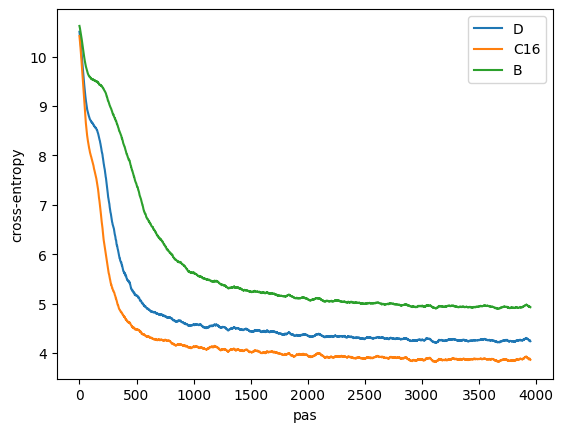

In [ ]:
for code in Losses:
    smooth = np.convolve(Losses[code], np.ones(50) / 50, mode='valid')
    plt.plot(smooth, label=code)
    print(code, 'loss finale (moyenne des 100 derniers pas) :', round(Losses[code][-100:].mean(), 3))

plt.xlabel('pas')
plt.ylabel('cross-entropy')
plt.legend()
plt.show()

#### Generation of tokens

In [ ]:
ROLL = 256              # événements générés après chaque prompt
TEMPERATURE = 1.0
PENALTY = 1.2           # pénalité de répétition (1.0 = aucune)

In [ ]:
def rep_penalty(logits, context, penalty=1.2):
    seen = torch.zeros_like(logits, dtype=torch.bool).scatter_(1, context, True)
    penalized = torch.where(logits > 0, logits / penalty, logits * penalty)
    return torch.where(seen, penalized, logits)


def sample_next_token(logits, temperature=1):
    probs = F.softmax(logits / temperature, dim=-1)
    return torch.multinomial(probs, num_samples=1)


def forward_last_digits(model, x, dp, ctx):
    with torch.autocast(DEV, dtype=torch.float16, enabled=(DEV == 'cuda')):
        logits = model(x[:, -ctx:], dp[:, -ctx:])[:, -1].float()
    return logits


###################### Generation ########################
@torch.no_grad()
def generate(model, prompt, dp_last, ctx=Context, roll=ROLL,
             temperature=1.0, penalty=1.2):
    """
    Génère `roll` tokens à partir de `prompt` (B, ctx).
    `dp_last` : (B,) dernier dp connu, répété sur tout le prompt.
    """
    x = prompt
    dp = dp_last[:, None].expand_as(prompt)

    for _ in range(roll):
        logits = forward_last_digits(model, x, dp, ctx)
        logits = rep_penalty(logits, x[:, -ctx:], penalty)
        nxt = sample_next_token(logits, temperature)

        x = torch.cat([x, nxt], dim=1)
        dp = torch.cat([dp, dp[:, -1:]], dim=1)

    return x[:, -roll:].cpu().numpy()


def sample_starts(tok, ctx, roll, n_prompt, seed=0):
    rng_starts = np.random.default_rng(seed)
    return np.sort(rng_starts.integers(ctx, len(tok) - roll - 1, n_prompt))


def build_prompts(tok, dp, starts, ctx):
    prompts = sample_windows(tok, starts - ctx, ctx)       # (n_prompt, ctx)
    dp_last = torch.tensor(dp[starts - 1]).to(DEV)         # (n_prompt,)
    return prompts, dp_last


def collect_real_targets(tok, starts, roll):
    return np.stack([tok[i: i + roll] for i in starts])

In [ ]:
def compare_distribution(real, gen):
    # W1 standardisé par la moyenne et l'écart-type du RÉEL : la référence est la même
    # pour tous les tokenizers, donc les W1 sont comparables entre eux
    a = real[np.isfinite(real)]
    b = gen[np.isfinite(gen)]
    ks = stats.ks_2samp(a, b).statistic
    wd = stats.wasserstein_distance((b - a.mean()) / a.std(),
                                    (a - a.mean()) / a.std())
    return ks, wd


def compare_actions(real_actions, gen_actions, n_classes=5):
    pr = np.bincount(real_actions.ravel(), minlength=n_classes) / real_actions.size
    pg = np.bincount(gen_actions.ravel(), minlength=n_classes) / gen_actions.size
    return 0.5 * np.abs(pg - pr).sum()


def compare_features(real, gen, feats):
    out = {}
    for f in feats:
        out[f] = compare_distribution(real[f], gen[f])
        out[f + '_series'] = (np.nanmean(real[f], axis=1),
                              np.nanmean(gen[f], axis=1))
    out['action'] = (compare_actions(real['action'], gen['action']), np.nan)
    out['side'] = (compare_actions(real['side'], gen['side'], n_classes=2), np.nan)
    return out

In [ ]:
def run(code, day, n_prompt, model, roll=None, temperature=None, penalty=None):
    # sans valeur donnée, on prend les paramètres de la cellule ROLL / TEMPERATURE / PENALTY
    if roll is None:
        roll = ROLL
    if temperature is None:
        temperature = TEMPERATURE
    if penalty is None:
        penalty = PENALTY

    tok = Tokens[code, day]
    dp = Tokens_dp[day]
    starts = sample_starts(tok, Context, roll, n_prompt)

    # génération par paquets de 32 prompts
    gen_tokens = []
    for s in np.array_split(starts, max(1, n_prompt // 32)):
        prompts, dp_last = build_prompts(tok, dp, s, Context)
        gen_tokens.append(generate(model, prompts, dp_last, Context, roll, temperature, penalty))
    gen_tokens = np.concatenate(gen_tokens)

    real = DEC[code].build(collect_real_targets(tok, starts, roll))
    gen = DEC[code].build(gen_tokens)

    out = compare_features(real, gen, FEATS)
    out['starts'] = starts / len(tok) * 24           # heure de la journée de chaque prompt
    out['gen_tokens'] = gen_tokens
    return out


def run_all(scenarios, corpora, models):
    results = {}
    torch.manual_seed(0)
    for name, days, n in scenarios:
        for c in corpora:
            for d in days:
                results[(name, c, d)] = run(c, d, n, models[c])
                print('fait :', name, c, d)
    return results

Un essai isolé : changer ici le tokenizer, le jour, le nombre de prompts, roll, la température ou la pénalité

In [ ]:
torch.manual_seed(0)

essai = run('D', testing_days[0], 32, Models['D'], roll=256, temperature=1.0, penalty=1.2)

for f in FEATS + ['action']:
    print(f, 'KS %.3f  W1 %.3f' % essai[f])

dt KS 0.154  W1 0.249
log_volume KS 0.078  W1 0.162
depth KS 0.054  W1 0.175
action KS 0.137  W1 nan


Les scénarios de la thèse

In [ ]:
SCENARIOS = [
    ('pass',     testing_days,     32),
    ('day-long', testing_days,     96),
    ('saturday', saturday_testing, 96),
]

RES = run_all(SCENARIOS, ['D', 'C16', 'B'], Models)

fait : pass D 20251222
fait : pass D 20251229
fait : pass C16 20251222
fait : pass C16 20251229
fait : pass B 20251222
fait : pass B 20251229
fait : day-long D 20251222
fait : day-long D 20251229
fait : day-long C16 20251222
fait : day-long C16 20251229
fait : day-long B 20251222
fait : day-long B 20251229
fait : saturday D 20251206
fait : saturday C16 20251206
fait : saturday B 20251206


Table 6 (jours de test, moyenne du 22 et du 29 décembre) et Table 7 (samedi)

In [ ]:
rows = []
for (name, code, d), v in RES.items():
    for f in FEATS + ['action', 'side']:
        rows.append({'run': name, 'code': code, 'day': d, 'feature': f, 'ks': v[f][0], 'w1': v[f][1]})
G = pd.DataFrame(rows)

print(G[G.run != 'saturday'].pivot_table(index=['feature', 'run'], columns='code', values=['ks', 'w1']).round(3).to_string())
print()
print(G[G.run == 'saturday'].pivot_table(index='feature', columns='code', values=['ks', 'w1']).round(3).to_string())

                        ks                   w1              
code                     B    C16      D      B    C16      D
feature    run                                               
action     day-long  0.074  0.130  0.112    NaN    NaN    NaN
           pass      0.095  0.127  0.102    NaN    NaN    NaN
depth      day-long  0.085  0.083  0.083  0.230  0.252  0.240
           pass      0.097  0.077  0.079  0.219  0.208  0.233
dt         day-long  0.048  0.043  0.064  0.100  0.087  0.132
           pass      0.060  0.057  0.116  0.103  0.122  0.201
log_volume day-long  0.083  0.180  0.081  0.097  0.391  0.170
           pass      0.084  0.159  0.081  0.094  0.335  0.152
side       day-long  0.070  0.081  0.073    NaN    NaN    NaN
           pass      0.095  0.081  0.072    NaN    NaN    NaN

               ks                   w1              
code            B    C16      D      B    C16      D
feature                                             
action      0.053  0.057  0.044   

#### Pass 2 et plancher de bruit

Mêmes 32 prompts, nouveau tirage : l'écart avec la pass 1 mesure le bruit de la génération en float16.

In [ ]:
# Pass 2 : les mêmes 32 prompts par jour, un nouveau tirage de la génération.
# L'écart avec la pass 1 donne le plancher de bruit (0,027 dans le mémoire).
RES2 = {}
for code in ['D', 'C16', 'B']:
    for d in testing_days:
        RES2[code, d] = run(code, d, 32, Models[code])

gap = [abs(RES2[code, d][f][0] - RES['pass', code, d][f][0])
       for code in ['D', 'C16', 'B'] for d in testing_days for f in FEATS]
print('écart KS maximal entre pass 1 et pass 2 (plancher de bruit) :', round(max(gap), 4))

rows2 = []
for (code, d), v in RES2.items():
    for f in FEATS + ['action', 'side']:
        rows2.append({'code': code, 'day': d, 'feature': f, 'ks': v[f][0], 'w1': v[f][1]})
print(pd.DataFrame(rows2).pivot_table(index='feature', columns='code', values=['ks', 'w1']).round(3).to_string())


écart KS maximal entre pass 1 et pass 2 (plancher de bruit) : 0.0525
               ks                   w1              
code            B    C16      D      B    C16      D
feature                                             
action      0.073  0.152  0.108    NaN    NaN    NaN
depth       0.081  0.076  0.081  0.224  0.198  0.236
dt          0.068  0.077  0.077  0.118  0.158  0.155
log_volume  0.081  0.177  0.081  0.074  0.385  0.167
side        0.069  0.048  0.063    NaN    NaN    NaN


Figures 3 à 8 : généré (rouge) contre réel (noir), un point par prompt, au fil de la journée

day-long D 20251222 log_volume ratio 1.23 corr +0.09
day-long D 20251222 dt ratio 0.94 corr -0.06
day-long D 20251229 log_volume ratio 1.25 corr +0.06
day-long D 20251229 dt ratio 0.95 corr -0.10


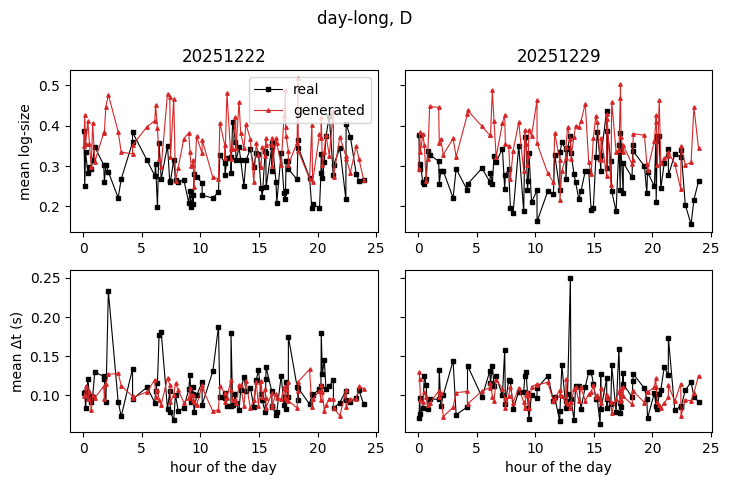

day-long C16 20251222 log_volume ratio 1.54 corr +0.12
day-long C16 20251222 dt ratio 0.95 corr +0.06
day-long C16 20251229 log_volume ratio 1.57 corr +0.06
day-long C16 20251229 dt ratio 0.98 corr +0.10


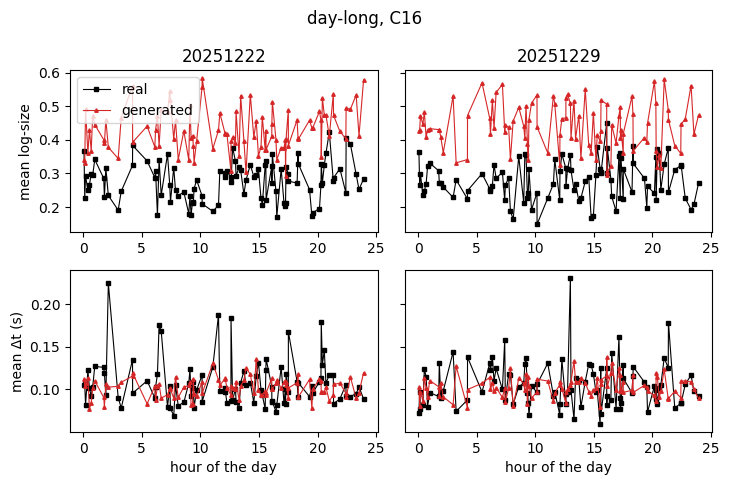

day-long B 20251222 log_volume ratio 1.08 corr +0.01
day-long B 20251222 dt ratio 0.94 corr +0.09
day-long B 20251229 log_volume ratio 1.12 corr -0.02
day-long B 20251229 dt ratio 0.98 corr +0.12


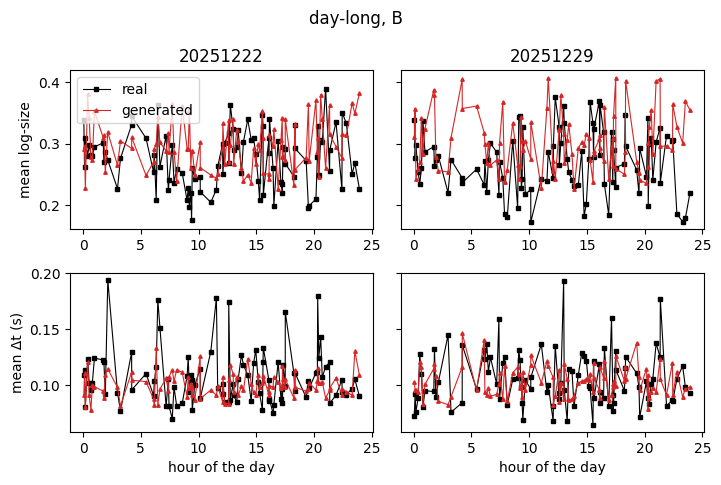

saturday D 20251206 log_volume ratio 1.38 corr +0.04
saturday D 20251206 dt ratio 0.95 corr +0.01


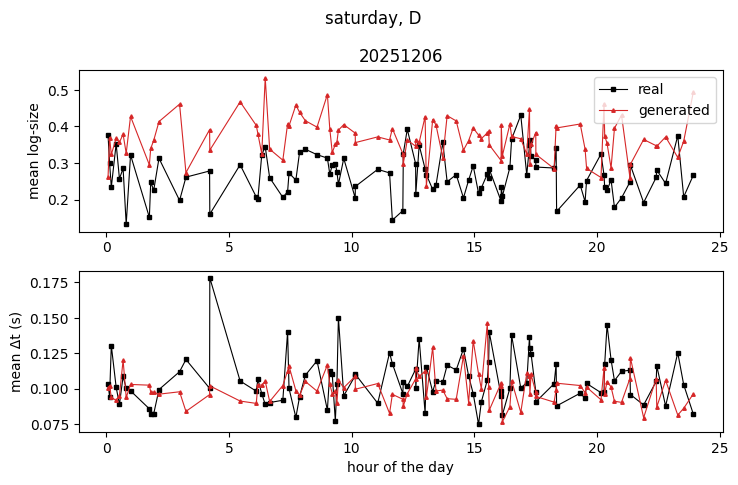

saturday C16 20251206 log_volume ratio 1.68 corr +0.16
saturday C16 20251206 dt ratio 0.97 corr +0.13


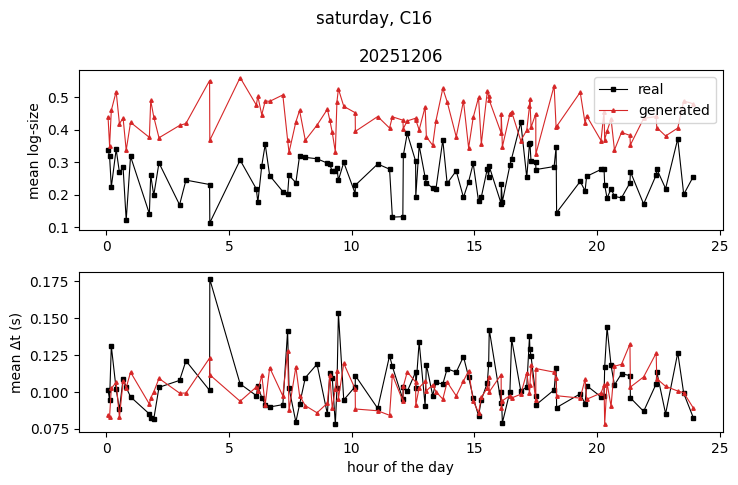

saturday B 20251206 log_volume ratio 1.29 corr +0.15
saturday B 20251206 dt ratio 0.96 corr +0.03


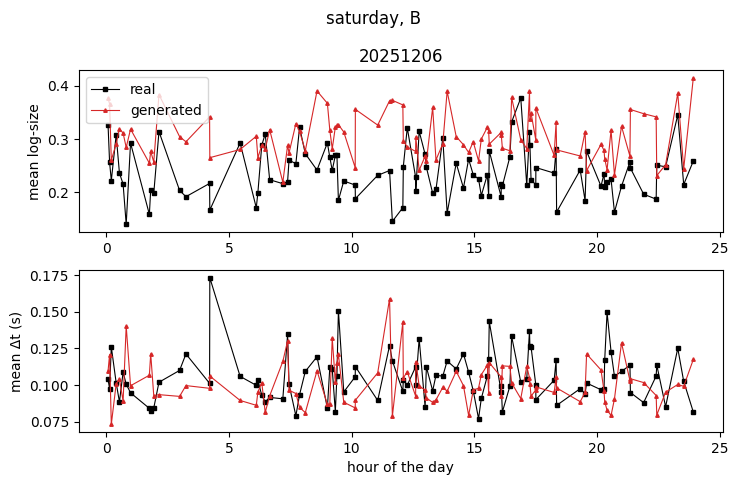

In [ ]:
for name, days in [('day-long', testing_days), ('saturday', saturday_testing)]:
    for code in ['D', 'C16', 'B']:
        fig, ax = plt.subplots(2, len(days), figsize=(7.4, 4.9), sharey='row', squeeze=False)

        for j, d in enumerate(days):
            r = RES[name, code, d]
            for i, f in enumerate(['log_volume', 'dt']):
                real, gen = r[f + '_series']
                ax[i, j].plot(r['starts'], real, 's-', c='k', ms=2.5, lw=.8, label='real')
                ax[i, j].plot(r['starts'], gen, '^-', c='C3', ms=2.5, lw=.8, label='generated')
                print(name, code, d, f, 'ratio %.2f corr %+.2f' % (gen.mean() / real.mean(), np.corrcoef(real, gen)[0, 1]))
            ax[0, j].set_title(str(d))
            ax[1, j].set_xlabel('hour of the day')

        ax[0, 0].set_ylabel('mean log-size')
        ax[1, 0].set_ylabel('mean Δt (s)')
        ax[0, 0].legend()
        fig.suptitle(f'{name}, {code}')
        fig.tight_layout()
        plt.show()

#### Distribution du généré contre le réel

Toutes les valeurs générées sont rassemblées et triées, comme les vraies valeurs qui ont suivi les mêmes prompts ; on compare leurs quantiles, surtout le 90e, le 99e et le 99,9e : les gros volumes générés sont-ils plus petits ou plus grands que les vrais ?

dt 
         q50                     q90                     q99                  q99.9                
       real   coded     gen    real   coded     gen    real   coded     gen   real   coded     gen
D    0.0967  0.0998  0.0845  0.1858  0.1853  0.1543  0.2671  0.2696  0.2213  0.282  0.2696  0.2696
C16  0.0967  0.0983  0.0983  0.1858  0.1893  0.1580  0.2671  0.2479  0.2171  0.282  0.2479  0.2479
B    0.0967  0.0958  0.0880  0.1858  0.1731  0.1731  0.2671  0.2038  0.2038  0.282  0.2038  0.2038 

log_volume 
        q50                     q90                     q99                     q99.9                  
      real   coded     gen    real   coded     gen    real   coded      gen     real    coded      gen
D    0.225  0.2280  0.2280  1.1168  0.7029  1.5400  6.8334  8.5407   8.5407  90.4729  60.5285  60.5285
C16  0.225  0.2300  0.2300  1.1168  1.1172  1.7415  6.8334  7.3669  15.2438  90.4729  15.2438  15.2438
B    0.225  0.2078  0.2078  1.1168  1.1668  1.1668  6.8334  3.0134   3.01

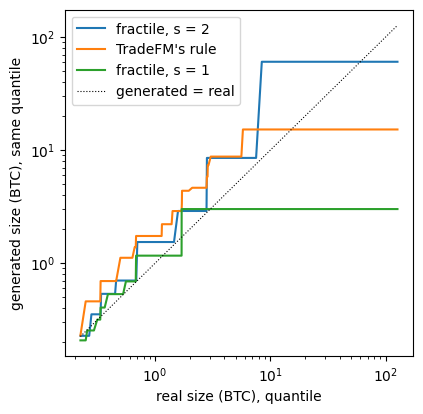

In [ ]:
# Distribution du généré contre le réel, jours de test (pass 1 et day-long réunis), pour les 5 variables d'itrade.
# Variables continues (Δt, taille, profondeur) : on rassemble toutes les valeurs générées et on les trie du plus petit
# au plus grand ; idem pour les vraies valeurs qui ont suivi les mêmes prompts. On compare les quantiles, surtout le
# 90e, le 99e et le 99,9e. Trois colonnes par quantile :
#   real  : la vraie valeur, brute
#   coded : la vraie valeur encodée puis décodée (ce que le code peut représenter au mieux)
#   gen   : la valeur générée
# Variables discrètes (action, côté) : part de chaque classe, réelle et générée.
# Δt en secondes, taille en BTC, profondeur en écart relatif au mid.

Q = [0.5, 0.9, 0.99, 0.999]
N_PROMPT = {'pass': 32, 'day-long': 96}
CODES = ['D', 'C16', 'B']


def to_unit(f, x):
    return np.expm1(x) if f == 'log_volume' else x       # seule la taille est stockée en log(1 + taille)


def pooled(code, f):
    real, coded, gen = [], [], []
    for name, n in N_PROMPT.items():
        for d in testing_days:
            tok = Tokens[code, d]
            starts = sample_starts(tok, Context, ROLL, n)          # les mêmes prompts que dans run()
            if f in FEATS:
                x = basement[d][f].values
                real.append(np.concatenate([x[i:i + ROLL] for i in starts]))
            else:
                real.append(np.ravel(DEC[code].build(collect_real_targets(tok, starts, ROLL))[f]))
            coded.append(np.ravel(DEC[code].build(collect_real_targets(tok, starts, ROLL))[f]))
            gen.append(np.ravel(DEC[code].build(RES[name, code, d]['gen_tokens'])[f]))
    out = {k: to_unit(f, np.concatenate(v)) for k, v in [('real', real), ('coded', coded), ('gen', gen)]}
    return {k: v[np.isfinite(v)] for k, v in out.items()}


DIST = {(code, f): pooled(code, f) for code in CODES for f in FEATS + ['action', 'side']}

for f in FEATS:
    rows = {}
    for code in CODES:
        v = DIST[code, f]
        rows[code] = {(f'q{100 * q:g}', k): np.quantile(v[k], q) for q in Q for k in ['real', 'coded', 'gen']}
    print(f, '\n', pd.DataFrame(rows).T.round(4).to_string(), '\n')

for f, n in [('action', 5), ('side', 2)]:
    shares = {('real', ''): np.bincount(DIST['D', f]['real'].astype(int), minlength=n) / DIST['D', f]['real'].size}
    for code in CODES:
        g = DIST[code, f]['gen'].astype(int)
        shares[('gen', code)] = np.bincount(g, minlength=n) / g.size
    print(f, '(part de chaque classe)\n', pd.DataFrame(shares).round(3).to_string(), '\n')

# les gros volumes générés sont-ils plus petits ou plus grands que les vrais ?
print('taille : généré / réel aux quantiles hauts')
print(pd.DataFrame({code: {f'q{100 * q:g}': np.quantile(DIST[code, 'log_volume']['gen'], q) /
                                           np.quantile(DIST[code, 'log_volume']['real'], q) for q in Q}
                    for code in CODES}).T.round(2).to_string())

# graphique quantile-quantile de la taille : valeurs triées générées contre valeurs triées réelles
p = 1 - np.logspace(-4, np.log10(0.5), 200)
plt.figure(figsize=(4.5, 4.5))
for code, label in [('D', 'fractile, s = 2'), ('C16', "TradeFM's rule"), ('B', 'fractile, s = 1')]:
    v = DIST[code, 'log_volume']
    plt.loglog(np.quantile(v['real'], p), np.quantile(v['gen'], p), label=label)
lim = np.quantile(DIST['D', 'log_volume']['real'], [0.5, 0.9999])
plt.loglog(lim, lim, 'k:', lw=.8, label='generated = real')
plt.xlabel('real size (BTC), quantile')
plt.ylabel('generated size (BTC), same quantile')
plt.legend()
plt.show()


#### Robustesse : contexte et rollout de 1 024 événements

La fenêtre de l'article source au lieu de 512 / 256. Les trois modèles sont réentraînés, puis génèrent en deux passes depuis les mêmes 32 prompts par jour de test.

In [ ]:
# Robustesse : contexte et rollout de 1 024 événements (la fenêtre de l'article source).
# Mêmes réglages que le modèle de référence, seule la fenêtre change : on réentraîne un modèle par code.
Context = 1024
Models1024, Losses1024 = {}, {}
for code in CODES:
    Models1024[code], Losses1024[code] = train(code)


D 1000 4.278
D 2000 4.356
D 3000 4.156
D 4000 4.196
C16 1000 3.823
C16 2000 3.961
C16 3000 3.683
C16 4000 3.866
B 1000 5.116
B 2000 4.972
B 3000 4.793
B 4000 4.835


In [ ]:
# Deux passes depuis les mêmes 32 prompts par jour de test, prompt et rollout de 1 024 événements.
RES1024 = {}
torch.manual_seed(0)
for p in ['pass 1', 'pass 2']:
    for code in CODES:
        for d in testing_days:
            RES1024[p, code, d] = run(code, d, 32, Models1024[code], roll=1024)
            print('fait :', p, code, d)
Context = 512        # retour à la fenêtre de référence

rows = []
for (p, code, d), v in RES1024.items():
    for f in FEATS + ['action', 'side']:
        rows.append({'run': p, 'code': code, 'day': d, 'feature': f, 'ks': v[f][0], 'w1': v[f][1]})
G1024 = pd.DataFrame(rows)
print(G1024.pivot_table(index=['feature', 'run'], columns='code', values=['ks', 'w1']).round(3).to_string())


fait : pass 1 D 20251222
fait : pass 1 D 20251229
fait : pass 1 C16 20251222
fait : pass 1 C16 20251229
fait : pass 1 B 20251222
fait : pass 1 B 20251229
fait : pass 2 D 20251222
fait : pass 2 D 20251229
fait : pass 2 C16 20251222
fait : pass 2 C16 20251229
fait : pass 2 B 20251222
fait : pass 2 B 20251229
                      ks                   w1              
code                   B    C16      D      B    C16      D
feature    run                                             
action     pass 1  0.067  0.094  0.093    NaN    NaN    NaN
           pass 2  0.074  0.080  0.099    NaN    NaN    NaN
depth      pass 1  0.095  0.078  0.120  0.239  0.237  0.240
           pass 2  0.088  0.079  0.093  0.229  0.240  0.235
dt         pass 1  0.030  0.040  0.047  0.061  0.069  0.066
           pass 2  0.043  0.029  0.038  0.082  0.064  0.077
log_volume pass 1  0.088  0.208  0.066  0.101  0.441  0.175
           pass 2  0.086  0.211  0.067  0.096  0.435  0.184
side       pass 1  0.065  0.126 

#### Incertitude : intervalles de confiance du KS de la taille

Bootstrap sur les prompts (fenêtres entières, avec remise), les mêmes prompts pour les trois codes : intervalle à 95 % du KS de chaque code et de l'écart entre deux codes.

In [ ]:
# Intervalles de confiance du KS de la taille, par bootstrap sur les prompts.
# Les événements d'une même fenêtre ne sont pas indépendants : on tire donc des fenêtres entières
# (des prompts) avec remise. Les mêmes prompts sont tirés pour les trois codes, ce qui donne
# aussi un intervalle pour l'écart entre deux codes (bootstrap apparié).
from scipy.stats import ks_2samp

CODES = ['D', 'C16', 'B']
N_BOOT = 1000
rng_boot = np.random.default_rng(1)


def ks(a, b):
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    return ks_2samp(a, b).statistic


def real_gen(r, code, d, f):
    # r : le résultat d'un run (RES[...] ou RES2[...]) ; renvoie réel et généré, une ligne par prompt
    tok = Tokens[code, d]
    n = r['gen_tokens'].shape[0]
    starts = sample_starts(tok, Context, ROLL, n)                     # les mêmes prompts que dans run()
    real = DEC[code].build(collect_real_targets(tok, starts, ROLL))[f]
    gen = DEC[code].build(r['gen_tokens'])[f]
    return np.asarray(real, float), np.asarray(gen, float)


RUNS = {'pass 1': lambda c, d: RES['pass', c, d],
        'pass 2': lambda c, d: RES2[c, d],
        'day-long': lambda c, d: RES['day-long', c, d]}

rows = []
for run_name, get in RUNS.items():
    data = {(c, d): real_gen(get(c, d), c, d, 'log_volume') for c in CODES for d in testing_days}
    point = {c: np.mean([ks(data[c, d][0].ravel(), data[c, d][1].ravel()) for d in testing_days]) for c in CODES}

    boot = {c: [] for c in CODES}
    for _ in range(N_BOOT):
        idx = {d: rng_boot.integers(0, len(data['D', d][0]), len(data['D', d][0])) for d in testing_days}
        for c in CODES:
            boot[c].append(np.mean([ks(data[c, d][0][idx[d]].ravel(), data[c, d][1][idx[d]].ravel())
                                    for d in testing_days]))
    boot = {c: np.array(v) for c, v in boot.items()}

    for c in CODES:
        lo, hi = np.percentile(boot[c], [2.5, 97.5])
        rows.append({'run': run_name, 'quantity': 'KS ' + c, 'value': point[c], 'low': lo, 'high': hi})
    for c in ['C16', 'B']:
        diff = boot[c] - boot['D']
        lo, hi = np.percentile(diff, [2.5, 97.5])
        rows.append({'run': run_name, 'quantity': 'KS ' + c + ' - KS D', 'value': point[c] - point['D'], 'low': lo, 'high': hi})

CI = pd.DataFrame(rows)
print(CI.round(3).to_string(index=False))

     run      quantity  value    low  high
  pass 1          KS D  0.081  0.061 0.114
  pass 1        KS C16  0.159  0.138 0.178
  pass 1          KS B  0.084  0.064 0.122
  pass 1 KS C16 - KS D  0.078  0.041 0.106
  pass 1   KS B - KS D  0.003 -0.014 0.021
  pass 2          KS D  0.081  0.062 0.119
  pass 2        KS C16  0.177  0.158 0.199
  pass 2          KS B  0.081  0.064 0.122
  pass 2 KS C16 - KS D  0.096  0.055 0.120
  pass 2   KS B - KS D  0.001 -0.012 0.019
day-long          KS D  0.081  0.066 0.099
day-long        KS C16  0.180  0.167 0.193
day-long          KS B  0.083  0.068 0.106
day-long KS C16 - KS D  0.100  0.081 0.115
day-long   KS B - KS D  0.003 -0.008 0.017


#### Structure séquentielle : autocorrélations à l'intérieur des fenêtres

Le KS compare des lois marginales. Ici on regarde l'ordre des événements : autocorrélation de la taille, du délai entre blocs et du côté aux retards 1 à 20, générée contre réelle.

In [ ]:
# Structure séquentielle : autocorrélation à l'intérieur des fenêtres de 256 événements,
# générées contre réelles, pour les cinq variables : taille, délai entre blocs, profondeur, côté,
# et pour l'action, l'indicatrice de chaque action fréquente (1 si l'événement est un add, 0 sinon, etc.).
# Jours de test, pass 1 et day-long réunis. Le réel est décodé par le même code que le généré.
LAGS = [1, 2, 5, 10, 20]
ACTIONS = {'add': 0, 'cancel': 2, 'reject': 4}


def acf(x, lags):
    # x : une ligne par fenêtre ; on centre sur la moyenne globale puis on moyenne les produits décalés
    x = np.asarray(x, float)
    x = np.nan_to_num(x - np.nanmean(x))
    var = np.mean(x * x)
    return np.array([np.mean(x[:, k:] * x[:, :-k]) / var for k in lags])


items = [(f, f, None) for f in ['log_volume', 'dt', 'depth', 'side']]
items += [('action: ' + a, 'action', k) for a, k in ACTIONS.items()]

rows = []
for label, f, k in items:
    for c in CODES:
        real, gen = [], []
        for name in ['pass', 'day-long']:
            for d in testing_days:
                r, g = real_gen(RES[name, c, d], c, d, f)
                if k is not None:                          # indicatrice de l'action k
                    r, g = (r == k).astype(float), (g == k).astype(float)
                real.append(r)
                gen.append(g)
        a_real = acf(np.concatenate(real), LAGS)
        a_gen = acf(np.concatenate(gen), LAGS)
        for lag, ar, ag in zip(LAGS, a_real, a_gen):
            rows.append({'feature': label, 'code': c, 'lag': lag, 'real': ar, 'gen': ag})

ACF = pd.DataFrame(rows)
print(ACF.pivot_table(index=['feature', 'code'], columns='lag', values=['real', 'gen']).round(3).to_string())

                       gen                               real                            
lag                     1      2      5      10     20     1      2      5      10     20
feature        code                                                                      
action: add    B     0.355  0.216  0.045 -0.011  0.014  0.328  0.196  0.102  0.073  0.071
               C16   0.404  0.241  0.021 -0.043 -0.009  0.328  0.196  0.102  0.073  0.071
               D     0.393  0.243  0.031 -0.036 -0.003  0.328  0.196  0.102  0.073  0.071
action: cancel B     0.652  0.453  0.165  0.034  0.028  0.619  0.458  0.279  0.163  0.102
               C16   0.647  0.436  0.113 -0.019  0.005  0.619  0.458  0.279  0.163  0.102
               D     0.671  0.472  0.139 -0.014 -0.006  0.619  0.458  0.279  0.163  0.102
action: reject B     0.328  0.286  0.229  0.174  0.147  0.577  0.551  0.501  0.457  0.406
               C16   0.295  0.250  0.191  0.141  0.127  0.577  0.551  0.501  0.457  0.406
          

#### Généré contre réel, fenêtre par fenêtre, pour les cinq variables

Complète les figures de la section 9.2 : corrélation entre les moyennes des fenêtres réelles et générées, et rapport des moyennes, pour la taille, le délai entre blocs, la profondeur, le côté et les actions fréquentes.

In [ ]:
# Généré contre réel, fenêtre par fenêtre, pour les cinq variables (complète les figures de la section 9.2).
# Pour chaque fenêtre : la moyenne de la taille, du délai entre blocs et de la profondeur absolue,
# la part des ordres côté ask, et la part de chaque action fréquente (add, cancel, reject).
# On donne la corrélation entre fenêtres réelles et générées, et le rapport des moyennes généré / réel.
ACTIONS = {'add': 0, 'cancel': 2, 'reject': 4}


def window_series(x, f, k=None):
    x = np.asarray(x, float)
    if k is not None:                      # part de l'action k dans chaque fenêtre
        return np.mean(x == k, axis=1)
    if f == 'depth':                       # profondeur signée : on prend sa valeur absolue
        x = np.abs(x)
    return np.nanmean(x, axis=1)


rows = []
for name, days in [('day-long', testing_days), ('saturday', saturday_testing)]:
    for c in CODES:
        for d in days:
            r = RES[name, c, d]
            items = [(f, f, None) for f in ['log_volume', 'dt', 'depth', 'side']]
            items += [('action: ' + a, 'action', k) for a, k in ACTIONS.items()]
            for label, f, k in items:
                real, gen = real_gen(r, c, d, f)
                wr, wg = window_series(real, f, k), window_series(gen, f, k)
                rows.append({'run': name, 'code': c, 'day': d, 'variable': label,
                             'corr': np.corrcoef(wr, wg)[0, 1], 'ratio': wg.mean() / wr.mean()})

W = pd.DataFrame(rows)
print(W.pivot_table(index=['run', 'variable'], columns=['code', 'day'], values='corr').round(2).to_string())
print()
print(W.pivot_table(index=['run', 'variable'], columns=['code', 'day'], values='ratio').round(2).to_string())

code                           B                        C16                          D                  
day                     20251206 20251222 20251229 20251206 20251222 20251229 20251206 20251222 20251229
run      variable                                                                                       
day-long action: add         NaN     0.35     0.49      NaN     0.52     0.39      NaN     0.36     0.35
         action: cancel      NaN    -0.18    -0.01      NaN     0.34     0.24      NaN     0.03     0.33
         action: reject      NaN     0.03     0.22      NaN     0.47     0.28      NaN     0.22     0.39
         depth               NaN    -0.08     0.01      NaN     0.20     0.23      NaN    -0.05    -0.06
         dt                  NaN     0.09     0.12      NaN     0.06     0.10      NaN    -0.06    -0.10
         log_volume          NaN     0.01    -0.02      NaN     0.12     0.06      NaN     0.09     0.06
         side                NaN     0.68     0.61     

#### Choix de s : le meilleur décodeur qui remplit tous les bins (erreur de Bennett)

Grille s = 1, 1,25, …, 6. Tokenizer et décodeur (moyenne de chaque bin) calibrés sur le 1er décembre, appliqués aux sept jours. Parmi les s qui remplissent les 16 bins de chaque variable sur chaque jour, on garde celui dont l'erreur quadratique (MSE / variance) moyenne est la plus faible.

In [ ]:
# Choix de s : le meilleur décodeur qui remplit tous les bins, au sens de l'erreur quadratique de Bennett.
# Le tokenizer et le décodeur (chaque bin remplacé par la moyenne de ses valeurs) sont calibrés sur le
# 1er décembre, puis appliqués tels quels à chacun des sept jours.
S_GRID = np.arange(1.0, 6.01, 0.25)
c_df = basement[cal]

rows = []
for s in S_GRID:
    tok = Fractile(c_df, s)
    for f in FEATS:
        # décodeur : moyenne de chaque bin sur le jour de calibration
        xc = decoder_token(f, c_df[f].values).scale()
        ic = tok.bins(f, c_df[f].values)
        ok = np.isfinite(xc)
        mean_bin = np.bincount(ic[ok], xc[ok], 16) / np.maximum(np.bincount(ic[ok], minlength=16), 1)

        for d in Days:
            x = decoder_token(f, basement[d][f].values).scale()
            ix = tok.bins(f, basement[d][f].values)
            ok = np.isfinite(x)
            x, ix = x[ok], ix[ok]
            rows.append({'s': s, 'day': d, 'feature': f,
                         'bins': len(np.unique(ix)),
                         'mse_var': ((x - mean_bin[ix]) ** 2).mean() / x.var()})

SEL = pd.DataFrame(rows)

# s qui remplit les 16 bins de chaque variable, sur chaque jour
full = SEL.groupby('s').bins.min() == 16

# erreur de Bennett (MSE / variance), moyenne sur les sept jours
err = SEL.pivot_table(index='s', columns='feature', values='mse_var', aggfunc='mean')
err['moyenne'] = err.mean(axis=1)
err['16 bins partout'] = full
print(err.round(4).to_string())

best = err[err['16 bins partout']]['moyenne'].idxmin()
print()
print('meilleur s :', best)

# détail par jour autour du meilleur s : bins utilisés et erreur
near = SEL[SEL.s.isin([best - 0.25, best, best + 0.25, 2.0])]
print(near.pivot_table(index=['s', 'day'], columns='feature', values=['bins', 'mse_var']).round(4).to_string())

feature   depth      dt  log_volume  moyenne  16 bins partout
s                                                            
1.00     0.8569  0.2972      0.1999   0.4514             True
1.25     0.8561  0.2908      0.1269   0.4246             True
1.50     0.8435  0.2854      0.0786   0.4025             True
1.75     0.8513  0.2811      0.0481   0.3935             True
2.00     0.8366  0.2797      0.0241   0.3801             True
2.25     0.8449  0.2780      0.0298   0.3842            False
2.50     0.8363  0.2769      0.0289   0.3807            False
2.75     0.8147  0.2754      0.0222   0.3708            False
3.00     0.8282  0.2726      0.0297   0.3768            False
3.25     0.8396  0.2701      0.0403   0.3833            False
3.50     0.8352  0.2679      0.0333   0.3788            False
3.75     0.8159  0.2692      0.0311   0.3721            False
4.00     0.7890  0.2749      0.0339   0.3659            False
4.25     0.7712  0.2748      0.0404   0.3621            False
4.50    

#### Autocorrélations, comme la figure 4 de TradeFM

L'autocorrélation en fonction du retard (1 à 50 événements), générée contre réelle, pour la taille, le délai entre blocs, la profondeur, le côté et les actions fréquentes.

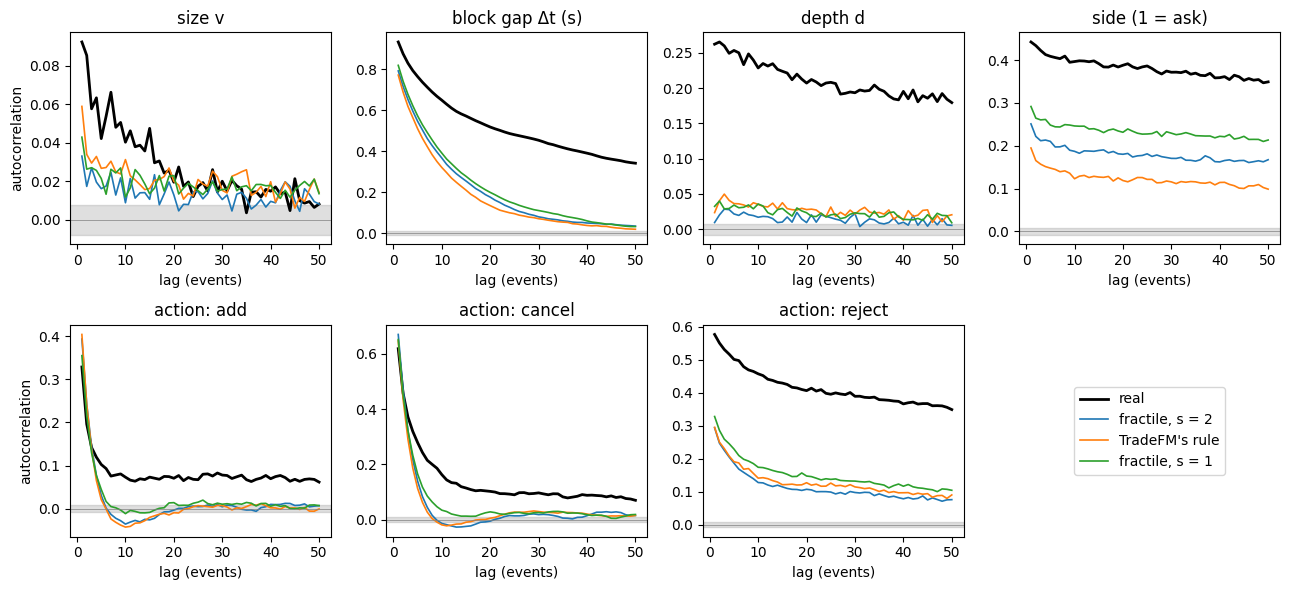

In [ ]:
# Autocorrélations générées contre réelles, tracées comme la figure 4 de TradeFM :
# l'autocorrélation en fonction du retard, une courbe par code, le réel en noir.
# Jours de test, pass 1 et day-long réunis ; le réel est décodé par le code s = 2
# (identique pour le côté et l'action). Bande grise : ±1,96 / sqrt(n), le seuil de significativité.
LAGS_PLOT = np.arange(1, 51)
PANELS = [('log_volume', None, 'size v'), ('dt', None, 'block gap Δt (s)'), ('depth', None, 'depth d'),
          ('side', None, 'side (1 = ask)'), ('action', 0, 'action: add'),
          ('action', 2, 'action: cancel'), ('action', 4, 'action: reject')]
NAMES = {'D': 'fractile, s = 2', 'C16': "TradeFM's rule", 'B': 'fractile, s = 1'}


def series(code, f, k, which):
    # toutes les fenêtres réelles ou générées d'un code, une ligne par fenêtre
    out = []
    for name in ['pass', 'day-long']:
        for d in testing_days:
            r, g = real_gen(RES[name, code, d], code, d, f)
            x = r if which == 'real' else g
            if k is not None:                       # indicatrice de l'action k
                x = (x == k).astype(float)
            out.append(x)
    return np.concatenate(out)


fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, (f, k, title) in zip(axes.ravel(), PANELS):
    real = series('D', f, k, 'real')
    ax.plot(LAGS_PLOT, acf(real, LAGS_PLOT), 'k-', lw=2, label='real')
    for c in CODES:
        ax.plot(LAGS_PLOT, acf(series(c, f, k, 'gen'), LAGS_PLOT), lw=1.2, label=NAMES[c])
    band = 1.96 / np.sqrt(real.size)
    ax.axhspan(-band, band, color='grey', alpha=.25)
    ax.axhline(0, c='grey', lw=.5)
    ax.set_title(title)
    ax.set_xlabel('lag (events)')

axes[0, 0].set_ylabel('autocorrelation')
axes[1, 0].set_ylabel('autocorrelation')
handles, labels = axes[0, 0].get_legend_handles_labels()
axes[1, 3].legend(handles, labels, loc='center')
axes[1, 3].axis('off')
fig.tight_layout()
plt.show()